# Tabular EDA: the structured sources of record
ADSP 32018 | snapshot v1 | tracker task 8 (Jack)

What the data looks like before we build Bronze/Silver/Gold on it: sizes, schema drift between
MIMIC v1.0 and v2.2, missing values, NHANES refused / don't-know codes, the NHANES zero
encoding (D10) and the patient-ID join across MIMIC and OMOP.

All profile numbers come from `scripts/profile_tables.py` (task 7, `results/<date>_p3_profile/
column_profile.csv`). Figures and tables written here go to the same run folder, so every number
is traceable. The database is opened read-only through `medrag.db.connect()`.

## 0. Setup

In [1]:
import json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 80, "display.width", 160)

from medrag import db

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = sorted((ROOT / "results").glob("*_p3_profile"))[-1]       # latest profile run
FIG, TAB = RUN / "figures", RUN / "tables"
FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)
INK, MUTED = "#3b6ea5", "#b8c4d1"        # one hue for magnitude, grey for context
BANDS = ["#dbe6f2", "#a9c3e0", "#6f9bc9", "#3b6ea5", "#1f3f66"]   # sequential, light -> dark

prof = pd.read_csv(RUN / "column_profile.csv")
con = db.connect()
print(RUN.name, prof.shape)

2026-11-10_p3_profile (1335, 14)


## 1. Inventory: schemas, tables, rows

In [2]:
tables = (prof.groupby(["schema", "table"])
          .agg(n_columns=("column", "size"), n_rows=("n_rows", "max")).reset_index())
inventory = (tables.groupby("schema")
             .agg(n_tables=("table", "size"), n_columns=("n_columns", "sum"),
                  n_rows=("n_rows", "sum"), largest_table_rows=("n_rows", "max")).reset_index())
inventory.loc[len(inventory)] = ["TOTAL", inventory.n_tables.sum(), inventory.n_columns.sum(),
                                 inventory.n_rows.sum(), inventory.largest_table_rows.max()]
inventory.to_csv(TAB / "inventory_by_schema.csv", index=False)
tables.to_csv(TAB / "inventory_by_table.csv", index=False)
inventory

,schema,n_tables,n_columns,n_rows,largest_table_rows
0,mimic_demo_v1_0_core,3,28,1565,1190
1,mimic_demo_v1_0_hosp,17,187,587961,109775
2,mimic_demo_v1_0_icu,7,96,718218,667703
3,mimic_demo_v2_2,1,1,100,100
4,mimic_demo_v2_2_hosp,22,229,637774,109775
5,mimic_demo_v2_2_icu,9,113,760726,668862
6,nhanes_2017_2018,14,314,111459,19643
7,omop_demo_v0_9,32,367,467840,338550
8,TOTAL,105,1335,3285643,668862


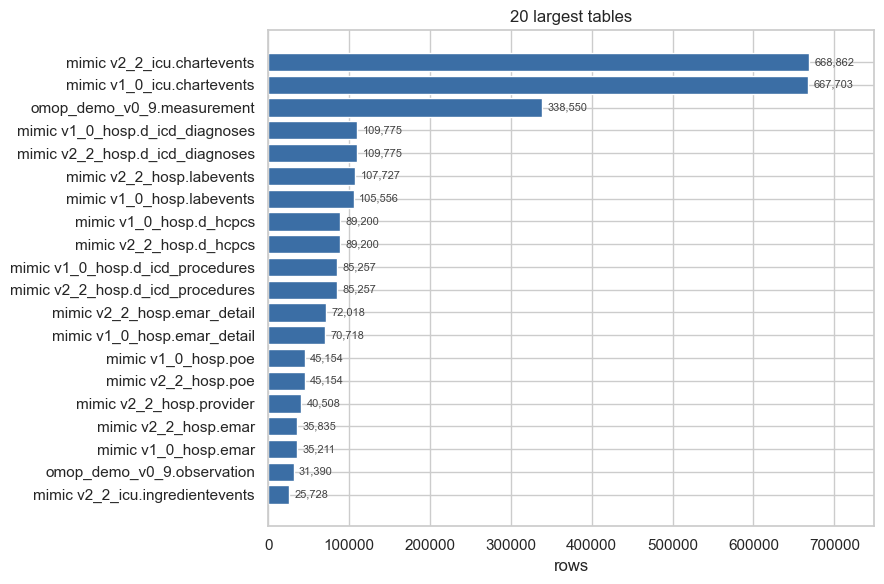

10 of 105 tables are empty


In [3]:
top = tables.nlargest(20, "n_rows").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.schema.str.replace("mimic_demo_", "mimic ") + "." + top.table, top.n_rows, color=INK)
for y, v in enumerate(top.n_rows):
    ax.text(v + top.n_rows.max() * 0.01, y, f"{v:,}", va="center", fontsize=8, color="#444")
ax.set(xlabel="rows", ylabel="", title="20 largest tables")
ax.set_xlim(right=top.n_rows.max() * 1.12)
plt.tight_layout(); plt.savefig(FIG / "largest_tables.png", dpi=160); plt.show()
print(f"{(tables.n_rows == 0).sum()} of {len(tables)} tables are empty")

## 2. Schema drift: MIMIC v1.0 vs v2.2
The OMOP demo was built from v1.0 (`core` + `hosp` + `icu`); current docs describe v2.2 (`core`
merged into `hosp`). This is a deliberate test case for P1, not something to fix. Below, v1.0
`core` and `hosp` are treated as one module and compared with v2.2 `hosp`.

In [4]:
def module(schema):
    m = re.match(r"mimic_demo_v(\d_\d)_?(\w*)", schema)
    return (m.group(1), "icu" if m.group(2) == "icu" else "hosp") if m else None

prof["mimic_version"] = prof.schema.map(lambda s: (module(s) or (None, None))[0])
prof["mimic_module"] = prof.schema.map(lambda s: (module(s) or (None, None))[1])
m = prof[prof.mimic_version.notna() & (prof["table"] != "demo_subject_id")].copy()
cols = (m.groupby(["mimic_version", "mimic_module", "table"])["column"]
        .apply(lambda s: set(c.lower() for c in s)).unstack("mimic_version"))
cols = cols.rename(columns={"1_0": "v1", "2_2": "v2"}).reset_index()
cols["status"] = np.where(cols.v1.isna(), "only in v2.2",
                          np.where(cols.v2.isna(), "only in v1.0", "both"))
def diff(a, b):
    return sorted(a - b) if isinstance(a, set) and isinstance(b, set) else []
cols["added_in_v2"] = [diff(b, a) for a, b in zip(cols.v1, cols.v2)]
cols["dropped_in_v2"] = [diff(a, b) for a, b in zip(cols.v1, cols.v2)]
drift = cols[["mimic_module", "table", "status", "added_in_v2", "dropped_in_v2"]].copy()
drift["changed"] = drift.added_in_v2.str.len() + drift.dropped_in_v2.str.len() > 0
drift.to_csv(TAB / "schema_drift_v1_0_vs_v2_2.csv", index=False)
print(drift.groupby(["mimic_module", "status"]).size().rename("tables").to_string())
print(f"\n{(drift.status == 'both').sum()} shared tables, "
      f"{(drift.changed & (drift.status == 'both')).sum()} with changed columns")
drift[(drift.status != "both") | drift.changed].reset_index(drop=True)

mimic_module  status      
hosp          both            20
              only in v2.2     2
icu           both             7
              only in v2.2     2

27 shared tables, 12 with changed columns


mimic_version,mimic_module,table,status,added_in_v2,dropped_in_v2,changed
0,hosp,admissions,both,"[admit_provider_id, race]",[ethnicity],True
1,hosp,d_labitems,both,[],[loinc_code],True
2,hosp,emar,both,[enter_provider_id],[],True
3,hosp,labevents,both,[order_provider_id],[],True
4,hosp,microbiologyevents,both,[order_provider_id],[],True
5,hosp,omr,only in v2.2,[],[],False
6,hosp,poe,both,[order_provider_id],[],True
7,hosp,prescriptions,both,"[formulary_drug_cd, order_provider_id, poe_id, poe_seq]",[],True
8,hosp,provider,only in v2.2,[],[],False
9,icu,caregiver,only in v2.2,[],[],False


## 3. Missing values
`null_pct` is the share of NULL cells per column. Only literal NULLs are counted here; NHANES
refused / don't-know codes are NOT nulls and are treated in section 4.

In [5]:
p = prof[prof.n_rows > 0].copy()
bins = [-0.01, 0, 10, 50, 99.99, 100]
labels = ["0% (complete)", "0-10%", "10-50%", "50-<100%", "100% (all null)"]
p["band"] = pd.cut(p.null_pct, bins=bins, labels=labels)
share = (p.groupby(["schema", "band"]).size().unstack(fill_value=0)
         .pipe(lambda d: d.div(d.sum(axis=1), axis=0) * 100).round(1))
share["columns"] = p.groupby("schema").size()
share.to_csv(TAB / "null_bands_by_schema.csv")
share

band,0% (complete),0-10%,10-50%,50-<100%,100% (all null),columns
schema,,,,,,
mimic_demo_v1_0_core,67.9,7.1,17.9,3.6,3.6,28
mimic_demo_v1_0_hosp,45.5,15.5,7.5,29.9,1.6,187
mimic_demo_v1_0_icu,83.3,0.0,5.2,7.3,4.2,96
mimic_demo_v2_2,100.0,0.0,0.0,0.0,0.0,1
mimic_demo_v2_2_hosp,48.9,15.7,8.3,25.8,1.3,229
mimic_demo_v2_2_icu,84.1,2.7,7.1,6.2,0.0,113
nhanes_2017_2018,18.2,9.6,25.8,46.2,0.3,314
omop_demo_v0_9,67.3,3.9,2.7,5.8,20.2,257


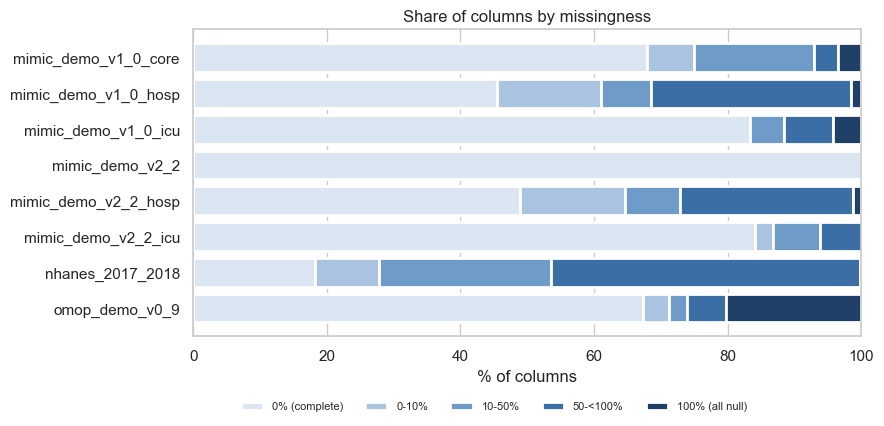

In [6]:
plot = share[labels].iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(plot))
for label, color in zip(labels, BANDS):
    ax.barh(plot.index, plot[label], left=left, color=color, label=label,
            edgecolor="white", linewidth=2)
    left += plot[label].values
ax.set(xlabel="% of columns", ylabel="", xlim=(0, 100), title="Share of columns by missingness")
ax.legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.18), frameon=False)
plt.tight_layout(); plt.savefig(FIG / "null_bands_by_schema.png", dpi=160); plt.show()

In [7]:
all_null = p[p.null_pct == 100][["schema", "table", "column", "dtype", "n_rows"]]
all_null.to_csv(TAB / "all_null_columns.csv", index=False)
print(all_null.groupby("schema").size().rename("all-null columns").to_string())
partial = (p[(p.null_pct > 0) & (p.null_pct < 100)]
           .nlargest(15, "null_pct")[["schema", "table", "column", "n_rows", "null_pct"]])
partial.to_csv(TAB / "most_missing_partial_columns.csv", index=False)
partial

schema
mimic_demo_v1_0_core     1
mimic_demo_v1_0_hosp     3
mimic_demo_v1_0_icu      4
mimic_demo_v2_2_hosp     3
nhanes_2017_2018         1
omop_demo_v0_9          52


,schema,table,column,n_rows,null_pct
892,nhanes_2017_2018,mcq_j,MCQ230D,8897,99.99
941,nhanes_2017_2018,smq_j,SMQ665B,6724,99.99
94,mimic_demo_v1_0_hosp,emar_detail,continued_infusion_in_other_location,70718,99.98
394,mimic_demo_v2_2_hosp,emar_detail,continued_infusion_in_other_location,72018,99.98
795,nhanes_2017_2018,diq_j,DIQ175X,8897,99.98
943,nhanes_2017_2018,smq_j,SMQ665D,6724,99.97
940,nhanes_2017_2018,smq_j,SMQ665A,6724,99.96
794,nhanes_2017_2018,diq_j,DIQ175W,8897,99.94
942,nhanes_2017_2018,smq_j,SMQ665C,6724,99.94
197,mimic_demo_v1_0_hosp,prescriptions,form_rx,18154,99.93


## 4. NHANES special codes (refused / don't know)
`special_codes` comes from each variable's codebook record, not from the values: `7` means
"Refused" in DIQ010 but "7 or more people" in DMDHHSIZ, so it is only counted where the codebook
says so. These rows must never be averaged as values.

In [8]:
nh = prof[prof.schema == "nhanes_2017_2018"].copy()
nh["non_null"] = nh.n_rows - nh.n_null
nh["special_pct"] = (100 * nh.n_special / nh.non_null.where(nh.non_null > 0)).round(2)
coded = nh[nh.n_special > 0]
print(f"{len(coded)} of {len(nh)} NHANES columns carry refused / don't-know codes; "
      f"{coded.n_special.sum():,} cells in total")

rows = []
for _, r in coded.iterrows():
    for c in json.loads(r.special_codes):
        rows.append({"table": r["table"], "column": r["column"], "code": c["value"],
                     "label": c["label"], "count": c["count"]})
codes = pd.DataFrame(rows)
by_code = (codes.groupby(["code", "label"]).agg(variables=("column", "nunique"),
           cells=("count", "sum")).reset_index().sort_values("cells", ascending=False))
by_code.to_csv(TAB / "nhanes_special_codes_by_code.csv", index=False)
by_code

124 of 314 NHANES columns carry refused / don't-know codes; 6,570 cells in total


,code,label,variables,cells
9,9999.0,Don't know,10,2089
2,9.0,Don't know,68,1943
5,99.0,Don't know,12,627
14,99999,Don't know,2,542
12,99999.0,Don't know,17,419
4,77.0,Refused,6,394
7,999.0,Don't know,9,363
0,7.0,Refused,20,50
3,33.0,Skin (don't know what kind),3,42
13,77777,Refused,2,35


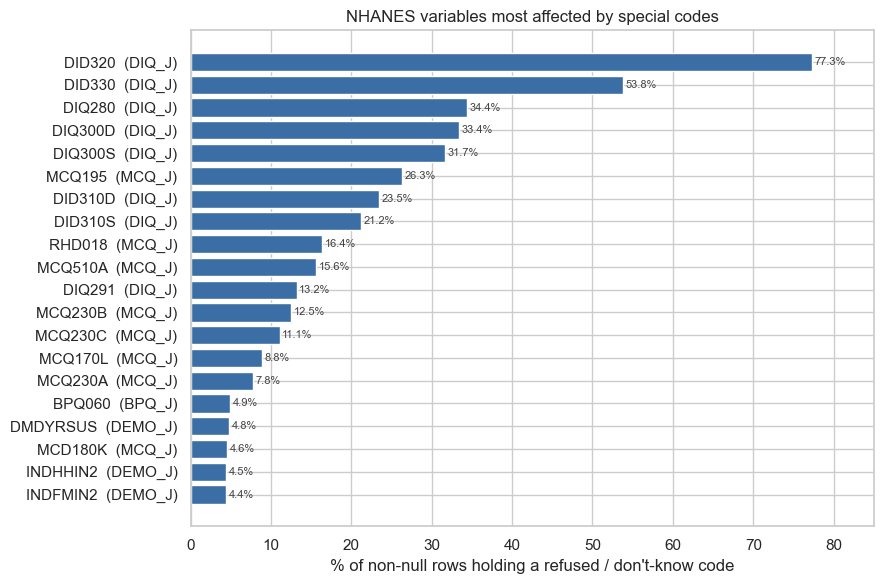

In [9]:
top = coded.nlargest(20, "special_pct").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.column + "  (" + top["table"].str.upper() + ")", top.special_pct, color=INK)
for y, v in enumerate(top.special_pct):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=8, color="#444")
ax.set_xlim(right=top.special_pct.max() * 1.1)
ax.set(xlabel="% of non-null rows holding a refused / don't-know code", ylabel="",
       title="NHANES variables most affected by special codes")
plt.tight_layout(); plt.savefig(FIG / "nhanes_special_codes_top20.png", dpi=160); plt.show()
coded[["table", "column", "non_null", "n_special", "special_pct", "special_codes"]] \
    .sort_values("special_pct", ascending=False).to_csv(TAB / "nhanes_special_codes_by_column.csv",
                                                       index=False)

## 5. NHANES zero encoding (D10)
Values documented as `0` are stored as `5.397605346934028e-79` in the frozen snapshot. Below we
count, per NHANES numeric column, the cells that fall strictly between 0 and 1e-70. The
profiler's `min` is also affected for these columns.

In [10]:
q = lambda s: '"' + s.replace('"', '""') + '"'
numeric = nh[nh.dtype.isin(["DOUBLE", "FLOAT", "REAL"])]
out = []
for _, r in numeric.iterrows():
    n = con.execute(f"SELECT count(*) FROM nhanes_2017_2018.{q(r['table'])} "
                    f"WHERE {q(r['column'])} > 0 AND {q(r['column'])} < 1e-70").fetchone()[0]
    if n:
        out.append({"table": r["table"], "column": r["column"], "n_rows": r.n_rows,
                    "cells_encoded_zero": n, "pct_of_rows": round(100 * n / r.n_rows, 2)})
zeros = pd.DataFrame(out).sort_values("cells_encoded_zero", ascending=False)
zeros.to_csv(TAB / "nhanes_encoded_zero_columns.csv", index=False)
print(f"{len(zeros)} of {len(numeric)} NHANES numeric columns hold encoded zeros "
      f"({zeros.cells_encoded_zero.sum():,} cells)")
print("profiler min < 1e-70 in", int(pd.to_numeric(numeric["min"], errors="coerce").between(1e-300, 1e-70).sum()), "columns")
zeros.head(15)

27 of 303 NHANES numeric columns hold encoded zeros (23,897 cells)
profiler min < 1e-70 in 27 columns


,table,column,n_rows,cells_encoded_zero,pct_of_rows
8,demo_j,DMDHHSZA,9254,6183,66.81
10,demo_j,DMDHHSZE,9254,6125,66.19
9,demo_j,DMDHHSZB,9254,4772,51.57
23,smq_j,SMQ895,6724,1711,25.45
24,smq_j,SMQ905,6724,844,12.55
25,smq_j,SMQ915,6724,720,10.71
21,smq_j,SMD100MN,6724,553,8.22
11,demo_j,WTMEC2YR,9254,550,5.94
4,demo_j,RIDAGEYR,9254,357,3.86
26,trigly_j,WTSAF2YR,3036,325,10.70


## 6. Patient ID integrity across MIMIC and OMOP
`omop.person.person_source_value` should equal MIMIC `subject_id` (as a string), and all of it
should fall inside the 100-patient demo list.

In [11]:
demo = set(con.execute("SELECT subject_id FROM mimic_demo_v2_2.demo_subject_id").df().subject_id)
rows = []
for schema, table, _, _ in prof[prof["column"] == "subject_id"][["schema", "table", "column",
                                                                  "ordinal"]].itertuples(index=False):
    if schema == "mimic_demo_v2_2":
        continue
    ids = set(con.execute(f"SELECT DISTINCT subject_id FROM {schema}.{q(table)}").df().subject_id)
    rows.append({"schema": schema, "table": table, "patients": len(ids),
                 "outside_demo_list": len(ids - demo)})
omop_ids = {str(v) for v in con.execute(
    "SELECT person_source_value FROM omop_demo_v0_9.person").df().person_source_value}
rows.append({"schema": "omop_demo_v0_9", "table": "person (person_source_value)",
             "patients": len(omop_ids), "outside_demo_list": len(omop_ids - {str(i) for i in demo})})
ids_check = pd.DataFrame(rows)
ids_check.to_csv(TAB / "patient_id_integrity.csv", index=False)
print(f"demo list: {len(demo)} patients; tables with subject_id: {len(ids_check) - 1}; "
      f"tables with ids outside the list: {(ids_check.outside_demo_list > 0).sum()}")
ids_check.sort_values("patients", ascending=False).head(12)

demo list: 100 patients; tables with subject_id: 48; tables with ids outside the list: 0


,schema,table,patients,outside_demo_list
0,mimic_demo_v1_0_core,admissions,100,0
34,mimic_demo_v2_2_hosp,poe_detail,100,0
22,mimic_demo_v2_2_hosp,admissions,100,0
23,mimic_demo_v2_2_hosp,diagnoses_icd,100,0
1,mimic_demo_v1_0_core,patients,100,0
28,mimic_demo_v2_2_hosp,labevents,100,0
31,mimic_demo_v2_2_hosp,patients,100,0
32,mimic_demo_v2_2_hosp,pharmacy,100,0
33,mimic_demo_v2_2_hosp,poe,100,0
35,mimic_demo_v2_2_hosp,prescriptions,100,0


## 7. Column shapes
Constant columns carry no information; key-like columns (every non-null value distinct) are
candidates for identifiers. Both matter for schema mapping and for deciding what to profile.

In [12]:
def family(t):
    t = t.upper()
    if t.startswith(("TIMESTAMP", "DATE", "TIME")): return "temporal"
    if t.startswith(("DOUBLE", "FLOAT", "REAL", "DECIMAL")): return "decimal"
    if "INT" in t: return "integer"
    return "text" if t.startswith("VARCHAR") else "other"

p["family"] = p.dtype.map(family)
nn = p.n_rows - p.n_null
p["constant"] = (p.n_distinct == 1) & (nn > 1)
p["key_like"] = (p.n_distinct == nn) & (nn > 1)
shape = p.groupby("schema").agg(columns=("column", "size"), constant=("constant", "sum"),
                                key_like=("key_like", "sum")).join(
    p.groupby(["schema", "family"]).size().unstack(fill_value=0))
shape.to_csv(TAB / "column_shapes_by_schema.csv")
shape

,columns,constant,key_like,decimal,integer,other,temporal,text
schema,,,,,,,,
mimic_demo_v1_0_core,28,0,10,0,9,0,7,12
mimic_demo_v1_0_hosp,187,5,9,10,60,2,19,96
mimic_demo_v1_0_icu,96,6,6,12,39,0,15,30
mimic_demo_v2_2,1,0,1,0,1,0,0,0
mimic_demo_v2_2_hosp,229,5,19,10,72,2,28,117
mimic_demo_v2_2_icu,113,5,7,15,51,0,18,29
nhanes_2017_2018,314,38,14,303,0,0,0,11
omop_demo_v0_9,257,21,35,5,113,0,44,95


## 8. Findings

In [13]:
tot = inventory.iloc[-1]
omop_null = share.loc["omop_demo_v0_9", "100% (all null)"]
print(f"- {int(tot.n_tables)} tables, {int(tot.n_columns):,} columns, {int(tot.n_rows):,} rows over "
      f"{len(inventory) - 1} schemas; the largest table has {int(tot.largest_table_rows):,} rows.")
print(f"- MIMIC v1.0 vs v2.2: {(drift.status == 'both').sum()} shared tables, "
      f"{(drift.status == 'only in v1.0').sum()} only in v1.0, "
      f"{(drift.status == 'only in v2.2').sum()} only in v2.2, "
      f"{(drift.changed & (drift.status == 'both')).sum()} shared tables with changed columns.")
print(f"- Missing values: {len(all_null)} all-null columns, {omop_null}% of the columns "
      f"in non-empty OMOP tables.")
print(f"- NHANES: {len(coded)} columns hold refused / don't-know codes "
      f"({coded.n_special.sum():,} cells) and {len(zeros)} numeric columns hold encoded zeros "
      f"({zeros.cells_encoded_zero.sum():,} cells).")
print(f"- Patient IDs: {(ids_check.outside_demo_list > 0).sum()} tables hold ids outside the "
      f"{len(demo)}-patient demo list.")
print(f"- Constant columns: {int(p.constant.sum())}; key-like columns: {int(p.key_like.sum())}.")

- 105 tables, 1,335 columns, 3,285,643 rows over 8 schemas; the largest table has 668,862 rows.
- MIMIC v1.0 vs v2.2: 27 shared tables, 0 only in v1.0, 4 only in v2.2, 12 shared tables with changed columns.
- Missing values: 64 all-null columns, 20.2% of the columns in non-empty OMOP tables.
- NHANES: 124 columns hold refused / don't-know codes (6,570 cells) and 27 numeric columns hold encoded zeros (23,897 cells).
- Patient IDs: 0 tables hold ids outside the 100-patient demo list.
- Constant columns: 80; key-like columns: 101.


Caveats: only 100 patients, so distributions are weak and rare codes may appear once or never;
the OMOP tables reflect one ETL team's choices, not universal truth.

In [14]:
con.close()